In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report
from xgboost import XGBClassifier

df = pd.read_csv("../data/processed/telco_clean.csv")

# leakage and non-predictive columns
drop_cols = ["customerid", "count", "country", "state", "city", "zip_code",
             "lat_long", "latitude", "longitude",
             "churn_label", "churn_score", "churn_reason", "cltv"]

y = df["churn_value"]
X = df.drop(columns=drop_cols + ["churn_value"])
X = pd.get_dummies(X, drop_first=True).astype(int)
print(X.shape)

(7043, 30)


In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(y_train.mean(), y_test.mean())

0.2653532126375577 0.2654364797728886


In [3]:
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
logreg.fit(X_train, y_train)

xgb = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                    eval_metric="logloss", random_state=42)
xgb.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [4]:
for name, model in [("LogReg", logreg), ("XGBoost", xgb)]:
    proba = model.predict_proba(X_test)[:, 1]
    print(name,
          "ROC-AUC:", round(roc_auc_score(y_test, proba), 3),
          "PR-AUC:", round(average_precision_score(y_test, proba), 3))
    print(classification_report(y_test, model.predict(X_test)))

LogReg ROC-AUC: 0.849 PR-AUC: 0.644
              precision    recall  f1-score   support

           0       0.85      0.88      0.87      1035
           1       0.64      0.57      0.60       374

    accuracy                           0.80      1409
   macro avg       0.75      0.73      0.73      1409
weighted avg       0.79      0.80      0.80      1409

XGBoost ROC-AUC: 0.853 PR-AUC: 0.666
              precision    recall  f1-score   support

           0       0.84      0.89      0.87      1035
           1       0.65      0.54      0.59       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.73      1409
weighted avg       0.79      0.80      0.79      1409



In [5]:
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import brier_score_loss
import matplotlib.pyplot as plt

xgb_cal = CalibratedClassifierCV(
    XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                  eval_metric="logloss", random_state=42),
    method="isotonic", cv=5)
xgb_cal.fit(X_train, y_train)

raw = xgb.predict_proba(X_test)[:, 1]
cal = xgb_cal.predict_proba(X_test)[:, 1]
print("Brier raw:", round(brier_score_loss(y_test, raw), 4),
      "| calibrated:", round(brier_score_loss(y_test, cal), 4))
print("ROC-AUC calibrated:", round(roc_auc_score(y_test, cal), 3))

Brier raw: 0.1341 | calibrated: 0.1326
ROC-AUC calibrated: 0.856


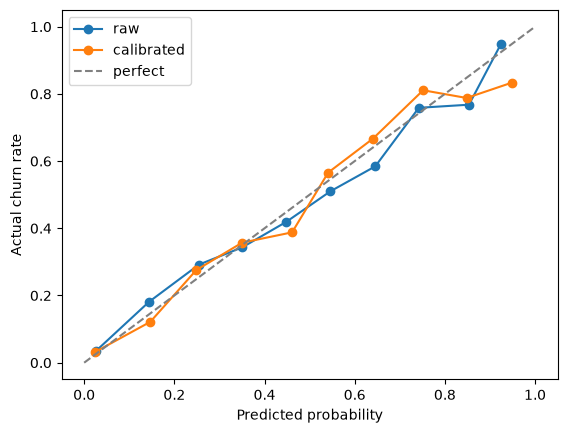

In [6]:
for name, p in [("raw", raw), ("calibrated", cal)]:
    frac, mean = calibration_curve(y_test, p, n_bins=10)
    plt.plot(mean, frac, marker="o", label=name)
plt.plot([0, 1], [0, 1], "--", color="gray", label="perfect")
plt.xlabel("Predicted probability")
plt.ylabel("Actual churn rate")
plt.legend()
plt.show()

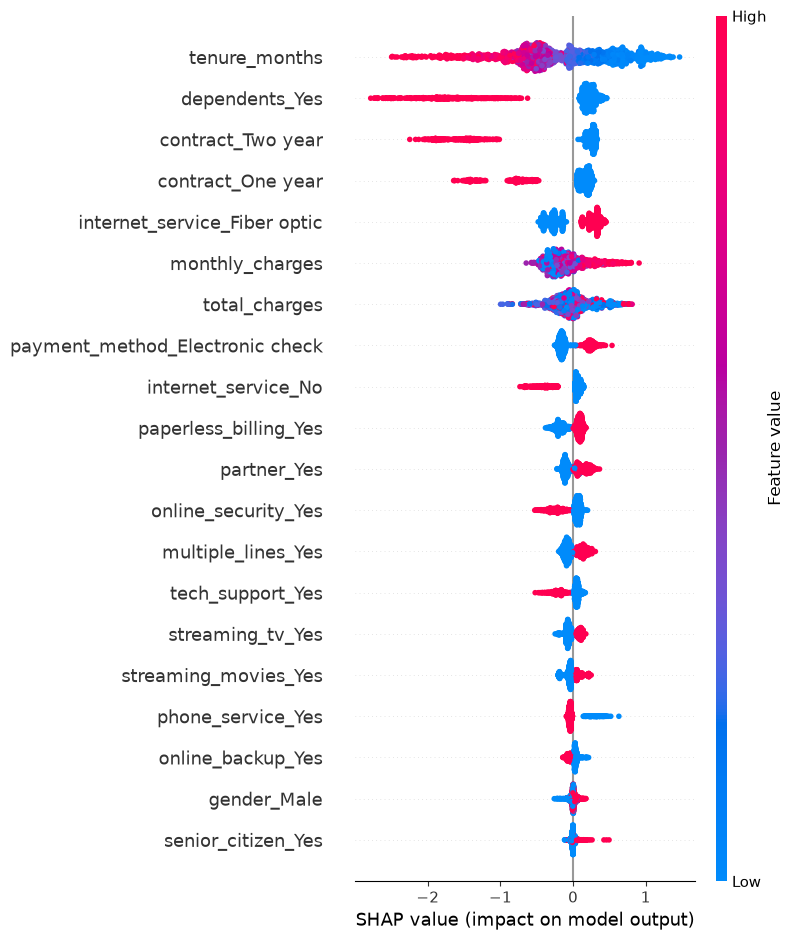

In [7]:
import shap

explainer = shap.TreeExplainer(xgb)
shap_values = explainer.shap_values(X_test)
shap.summary_plot(shap_values, X_test)

In [8]:
import joblib
joblib.dump(xgb_cal, "../models/xgb_calibrated.joblib")
joblib.dump(list(X.columns), "../models/feature_columns.joblib")

['../models/feature_columns.joblib']

In [9]:
shap.summary_plot(shap_values, X_test, show=False)
plt.savefig("../reports/figures/shap_summary.png", bbox_inches="tight", dpi=150)
plt.close()